# Analyzing a Single Damped Sinusoid

This is the simplest possible example: analyzing a single damped sinusoid in <u>*white Gaissian noise*</u>. We use this case study to demonstrate some basic features of ringdown!

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"          # single-threaded BLAS

import numpyro
numpyro.set_host_device_count(4)             # 4 CPU devices for parallel chains
numpyro.enable_x64()                         # double precision

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import ringdown as rd
import numpy as np
import matplotlib.pyplot as plt
import arviz_plots

In [3]:
import arviz as az
import seaborn as sns
import pandas as pd

sns.set_theme(context='notebook', palette='colorblind')

## Data

### Signal

First, let's create a time array based on a specified sampling rate and duration, centered around a target time t<sub>0</sub>.

In [4]:
# define sampling rate and duration (make these powers of two)
fsamp = 8192
duration = 4
t0 = 0

delta_t = 1/fsamp
tlen = int(round(duration / delta_t))
epoch = t0 - 0.5*tlen*delta_t

time = np.arange(tlen)*delta_t + epoch

We can use the above timestamps to create a simulated damped sinusoid starting at t<sub>0</sub>. We can extend the signal before t<sub>0</sub> to be a corresponding ring-up (the inference is insensitive to what happens before t<sub>0</sub>, so we can always just let the signal vanish for t < t<sub>0</sub>, as long as no step in the data conditioning involves taking a Fourier transform).

In [5]:
wf_kws = dict(
    A = 5,
    phi = 0,
    f = 250,
    gamma = 250,
)

def get_signal(time, A, phi, f, gamma):
    s = A*np.cos(2*np.pi*f*(time-t0) - phi)*np.exp(-gamma*abs(time-t0))
    return rd.Data(s, index=time)

signal = get_signal(time, **wf_kws)

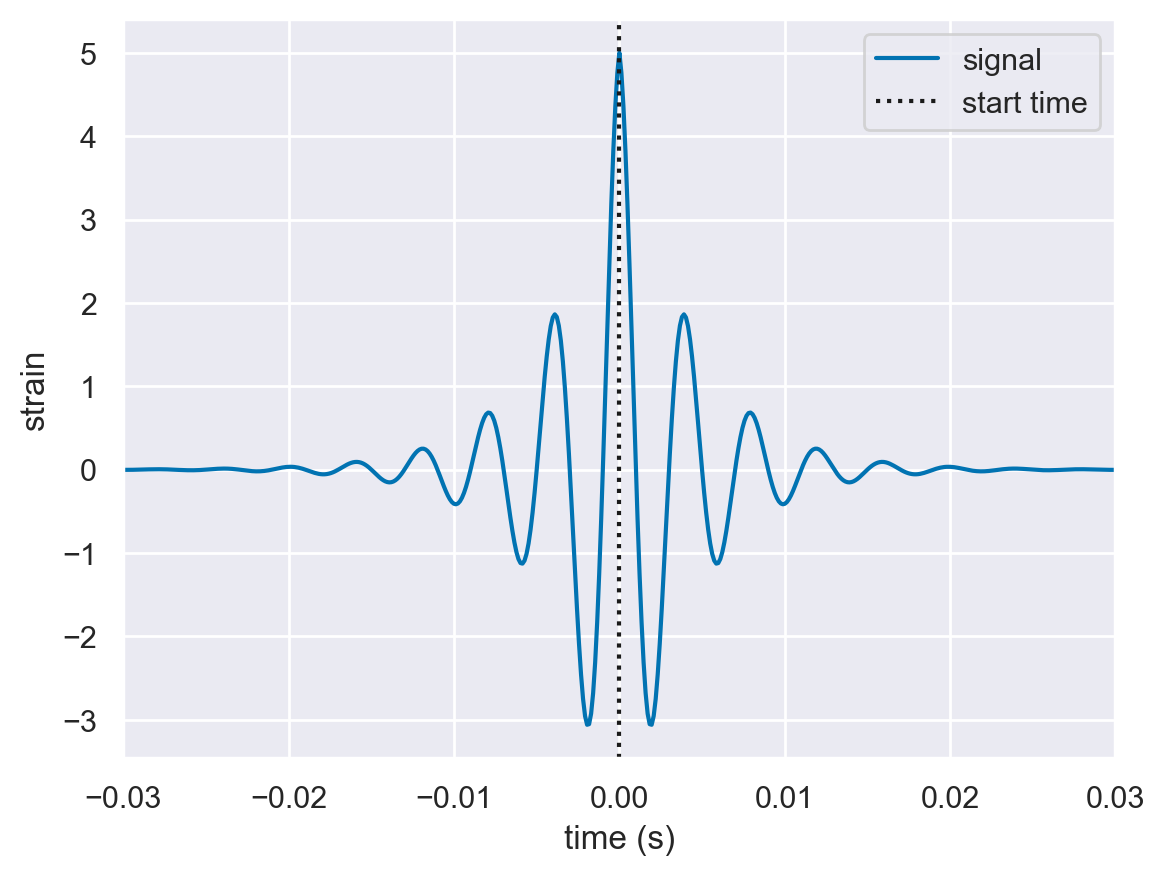

In [6]:
signal.plot(label='signal')
plt.axvline(t0, ls=':', c='k', label='start time')
plt.xlim(-0.03, 0.03)
plt.xlabel('time (s)')
plt.ylabel('strain')
plt.legend();

### Noise

Let's add some white Gaussian noise to the signal to obtain our data. This means the <u>*auto-correlation function (ACF)*</u> of the noise will be 𝜌⁡(𝜏) =𝛿⁡(𝜏).

In [7]:
rng = np.random.default_rng(12345)
data = signal + rng.normal(0, 1, len(signal))

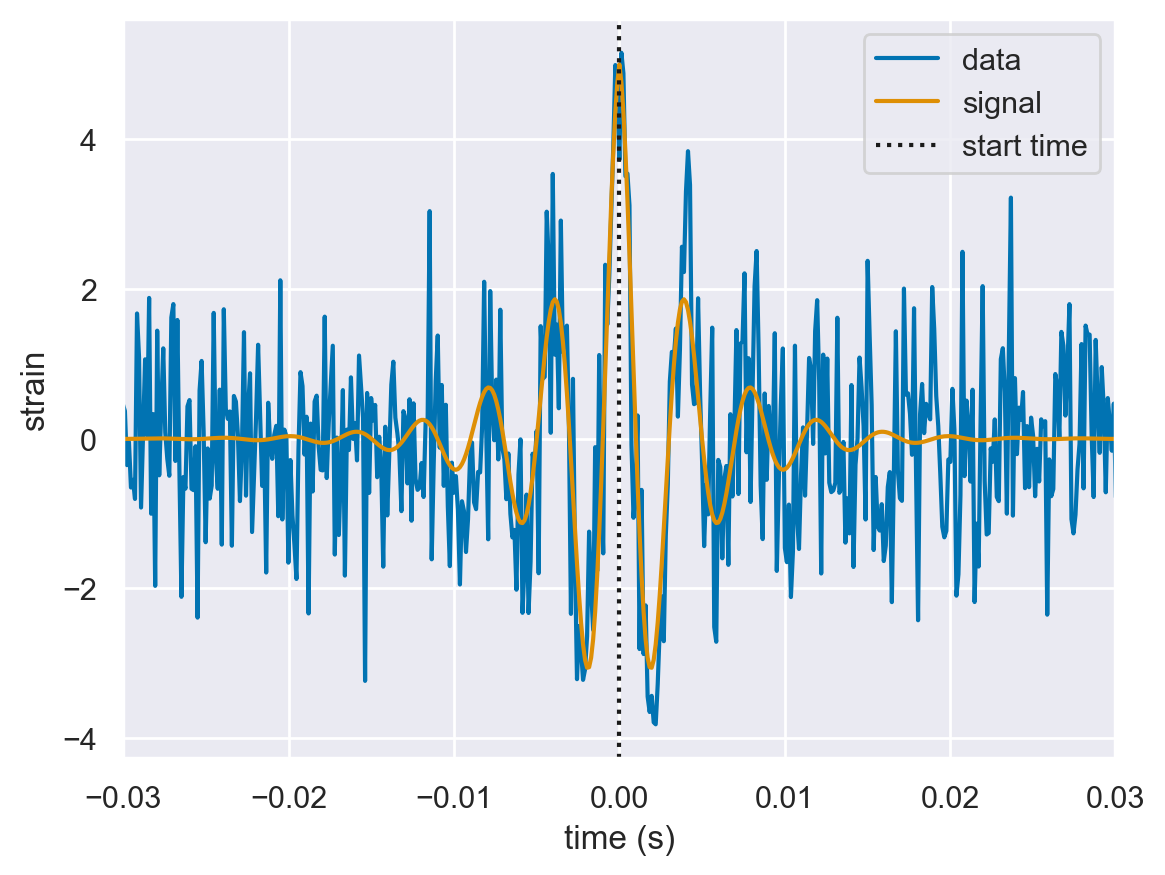

In [8]:
data.plot(label='data')
signal.plot(label='signal')
plt.axvline(t0, ls=':', c='k', label='start time')
plt.xlim(-0.03, 0.03)
plt.xlabel('time (s)')
plt.ylabel('strain')
plt.legend();

For our ringdown analysis, we will need the ACFs corresponding to the noise, which we could estimate empirically from the data; in this case, however, we know the ACF to be a delta function at the origin (corresponding to standard Gaussian noise).

In [9]:
acf = rd.AutoCovariance(np.zeros_like(data), delta_t=data.delta_t)
acf.iloc[0] = 1

When working with white noise it is unnecessary to work with the ACF: all we have is a variance (in this case, 𝜎<sup>2</sup>=1) and the likelihood simplifies drastically. However, in real life we never have white noise, so ringdown expects an ACF and cannot currently accomodate a scalar variance.

## Fit

We are now ready to analyze the ringdown! Let’s create a Fit object and set up the analysis. To do this, we first need to specify the model to be fit and the number (or kind) of modes to be used. In this case, we will be using the ftau model, which is parameterized in terms of damped sinusoids with generic frequencies 𝑓<sub>𝑛</sub>, damping rates 𝛾<sub>𝑛</sub> =1/𝜏<sub>𝑛</sub>, amplitudes 𝐴<sub>𝑛</sub>, and phases 𝜙<sub>𝑛</sub>, defined such that successive modes are ordered in terms of damping rate (𝛾<sub>𝑛</sub> < 𝛾<sub>𝑛+1</sub>); for this is example, we will only inject and recover a single mode. Since we are simulating a simple damped sinusoid in a single data stream, we need to use the single_polarization argument so that the fit does not look for two gravitational wave polarizations.

In [10]:
fit = rd.Fit(modes=1, single_polarization=True)
fit.add_data(data, acf=acf) #adding the data and the ACF

Now, let’s specify a target for the analysis, i.e., the desired start time and analysis segment duration.

Note: We will pick a very short duration to make this is example run fast, but in a real analysis this should be set based on the timescale imposed by the whitening filter and might well exceed the duration of the unwhitened signal.

In [11]:
fit.set_target(t0, duration=0.03)

Finally, let’s set some reasonable prior based on our knowledge of the true signal.

In [12]:
fit.update_model(a_scale_max=20, f_min=50, f_max=500, g_min=50, g_max=500)
fit.model_settings

{'single_polarization': True,
 'a_scale_max': 20,
 'f_min': 50,
 'f_max': 500,
 'g_min': 50,
 'g_max': 500}

In [13]:
fit.run()

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

TypeError: only 0-dimensional arrays can be converted to Python scalars

## Results

After the run is done, fit.result contains an Arviz object giving our results:

In [ ]:
az.summary(fit.result, var_names=['a', 'phi', 'f', 'g'])

We can plot a trace, and see visually that the sampling seems OK for all the different chains (chains are represented by a different linestyle):

In [ ]:
fit.result.plot_trace(var_names=['a', 'phi', 'f', 'g']);
plt.subplots_adjust(hspace=0.5)

This is a very useful plot to diagnose the quality of a fit.

### Posterior

We can also make a corner plot using Seaborn, and check that the posterior supports the truth.

In [ ]:
df = pd.DataFrame({
    r'$A$': fit.result.posterior.a.values.flatten(),
    r'$\phi$': fit.result.posterior.phi.values.flatten(),
    r'$f / \mathrm{Hz}$': fit.result.posterior.f.values.flatten(),
    r'$\gamma  / \mathrm{Hz}$': fit.result.posterior.g.values.flatten()
})
pg = sns.PairGrid(df, diag_sharey=False, corner=True)
pg.map_diag(sns.kdeplot);
pg.map_lower(sns.scatterplot, marker='.', alpha=0.02);
pg.map_lower(rd.utils.kdeplot, levels=[0.9, 0.5, 0.1]);

# plot true values
for i, vi in enumerate(wf_kws.values()):
    for j, vj in enumerate(wf_kws.values()):
        if i >= j:
            pg.axes[i,j].axvline(vj, ls=':')
            if i != j:
                pg.axes[i,j].axhline(vi, ls=':')

### Prior

The above posterior was obtained under ringdowns default prior given the provided settings. This prior is designed to be flat in amplitude below a_scale_max/2, and tapering smoothly for higher values. You can always check the prior explicitly by rerunning your Fit using the prior=True option; the result will be saved in fit.prior.

In [ ]:
fit.run(prior=True)

In [ ]:
fit.prior.plot_trace(var_names=['a', 'phi', 'f', 'g']);

In [ ]:
a = fit.prior.posterior.a.values.flatten()
sns.histplot(a[a<fit.model_settings['a_scale_max']/4], label='posterior')
plt.xlabel('$A$');

### Reconstructions

Get mean signal reconstructions at each detector and plot them against the truth.

In [ ]:
# median reconstruction and 90%-credible envelope
wfs = [np.quantile(fit.result.h_det.values, q, axis=(0,1))[0,:]
       for q in [0.5, 0.95, 0.05]]
wfs = [rd.Data(wf, index=fit.analysis_data[None].time) for wf in wfs]

In [ ]:
# plot reconstructions computed above
m, u, d = wfs
l, = plt.plot(m, label='measured')
plt.fill_between(m.time, u, d, color=l.get_color(), alpha=0.25)

# plot truth (using time mask to select right times)
plt.plot(signal[m.time], c='k', ls='--', label='truth')

plt.xlabel('time (s)')
plt.ylabel('strain')
plt.legend();

Let’s compute the <u>*recovered matched filter SNR*</u>, defined as 𝜌 =⟨ℎ∣𝑑⟩/⟨ℎ∣ℎ⟩. We can obtain a posterior on the recovered matched filter SNR by computing this quantity from random draws of the posterior; the Fit object can do this automatically (and efficiently) for us.

In [ ]:
snrs_mf = fit.result.compute_posterior_snrs(optimal=False, network=True)

Also compute the injected matched-filter SNR for reference:

In [ ]:
injsnr_mf = np.dot(signal[m.time], data[m.time]) / np.linalg.norm(signal[m.time])

In [ ]:
sns.kdeplot(snrs_mf)
plt.axvline(injsnr_mf, ls='--');
plt.xlabel('matched filter network SNR');

## Saving

If you want, you can save the fit result to disk as follows:

In [ ]:
fit.result.to_netcdf('myfit.nc')

And you can load that by doing:

In [ ]:
cached_result = rd.Result.from_netcdf('myfit.nc')

This new object, cached_result, will be the same as the original fit.result.

# Fitting Quasi-Normal Modes in GW150914

We demonstrate how to use ringdown to fit damped sinusoids in data from the first LIGO detection, GW150914. We will make a number of pedagogical plots along the way, the actual fit should take under 2 minutes in a modern desktop computer.

## Data

In this example, we will load GW150914 directly from disk. To do this, we first download it from the Gravitational-Wave Open Science Center. We grab 32s of data in each IFO, sampled at 16 kHz. Ringdown supports reading both frame files and HDF5 files from GWOSC.

In [ ]:
!wget -nc https://gwosc.org/eventapi/html/GWTC-1-confident/GW150914/v3/H-H1_GWOSC_16KHZ_R1-1126259447-32.hdf5
!wget -nc https://gwosc.org/eventapi/html/GWTC-1-confident/GW150914/v3/L-L1_GWOSC_16KHZ_R1-1126259447-32.hdf5

!openssl md5 H-H1_GWOSC_16KHZ_R1-1126259447-32.hdf5
!openssl md5 L-L1_GWOSC_16KHZ_R1-1126259447-32.hdf5

## Fitting Kerr Modes 

We will initialize our Fit object by specifying which modes we would like to fit. We will first carry out a Kerr fit containing both the <u>*fundamental quadrupolar mode*</u> and <u>*an overtone*</u>.

In [ ]:
fit = rd.Fit(modes=[(1, -2, 2, 2, 0), (1, -2, 2, 2, 1)])

In [ ]:
fit.set_target(1126259462.4083147, ra=1.95, dec=-1.27, psi=0.82, duration=0.2) 
#setting the analysis time, tarket sky location, anf analysis duration corresponding to an estimate of the peak of GW150914

## Data Preparation

We begin by loading some data. The fit offers a variety of ways for doing this, but in this example we will load them directly from files on disk.

In [ ]:
fit.load_data('{i}-{ifo}_GWOSC_16KHZ_R1-1126259447-32.hdf5', ifos=['H1', 'L1'], kind='GWOSC')

In [ ]:
for ifo, data in fit.data.items():
    data[::4].plot(label=ifo)
plt.xlabel(r'$t_\mathrm{GPS} / \mathrm{s}$');
plt.ylabel(r'$h(t)$');
plt.legend(loc='best');

Now that we’ve got the strain loaded up, we want to condition it a bit. LIGO does not have very good high-frequency sensitivity; also, our modes do not have a lot of high-frequency content. Additionally, LIGO contains a lot of low-frequency noise and our templates do not have a lot of power at low frequencies. Here are estimated noise PSDs for our data:

In [ ]:
for ifo, data in fit.data.items():
    plt.loglog(data.get_psd().iloc[1:], label=ifo)
plt.xlabel(r'$f / \mathrm{Hz}$');
plt.ylabel(r'$P\left( f \right) / \mathrm{Hz}^{-1}$');
plt.legend(loc='best');

### Data Conditioning

In [ ]:
fit.condition_data(ds=8, f_min=20)

We can visualize the segment of conditioned analysis data as another sanity check:

In [ ]:
for i, d in fit.analysis_data.items():
    d.plot(label=i)
    plt.axvline(fit.start_times[i], ls='--', alpha=0.5, lw=3, c='gray')
plt.xlabel(r'$t_\mathrm{GPS} / \mathrm{s}$');
plt.ylabel(r'$h(t)$');
plt.legend(loc='best');

The wave arrived first at Livingston, then at Hanford, which is why the time segments are not exactly aligned.

## Autocovariance Function¶

 You can load estimates of the ACF from disk, derive it from a PSD, or estimate it directly from the data. We do the latter below, with some default options.

In [ ]:
fit.compute_acfs(f_min=20)

We can use the ACFs to whiten the analysis data and plot it once again.

In [ ]:
wd = fit.whiten(fit.analysis_data)
for i, d in wd.items():
    d.plot(label=i)
plt.xlabel(r'$t_\mathrm{GPS} / \mathrm{s}$');
plt.ylabel(r'whitened $h(t)$');
plt.legend(loc='best');

The signal is visible towards the beginning of the whitened data.

## Run Fit

We are almost ready to run the fit. Before sampling over the posterior on modes, we need to set up some priors with reasonable choices. For a vanilla Kerr fit with generic mode polarizations (not parametrized in terms of a source inclination), we only need to specify an amplitude scale, and a mass range.

In [ ]:
fit.update_model(a_scale_max=5e-20, m_min=40.0, m_max=140.0, cosi=-1)

We are finally ready to run! This should only take a few seconds on a modern desktop computer using CPUs.

In [ ]:
fit.run()

In [ ]:
fit.result

The result of our fit is held in fit.result. This is just an xarray.DataTree object (the structure ArviZ uses to store inference data), with some additional ringdown-specific functionality. As such we can use all tools in ArviZ easily.

In [ ]:
az.summary(fit.result, var_names=['a', 'm', 'chi', 'f', 'g'])

We can visualize the result of the fit using a trace plot. This allows us to visualize the chains and diagnose any potential divergences.

In [ ]:
fit.result.plot_trace(var_names=['m', 'chi', 'a']);

We can access the posterior samples directly in fit.result.posterior. We can also obtain a Pandas DataFrame with all chains stacked together. This can be really convenient for plotting and other manipulations.

In [ ]:
# draw 500 samples from the posterior
fit.result.get_parameter_dataframe(500, latex=True)

## Plot results

In [ ]:
### Remnant Mass and Spin

In [ ]:
from arviz_plots import add_lines

pm = az.plot_pair(fit.result, var_names=['m', 'chi'])
add_lines(pm, values={'m': [70], 'chi': [0.7]});